# code_083 · Nearest-neighbour prediction and retrieval

**Book:** section 17.2. A self-contained similarity-and-margin laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_17_GUIDE.md), [run evidence](../CHAPTER_17_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_083).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1783;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1783


<a id="prediction"></a>
## Fit neighborhoods on admitted historical cases

Generate independent training300/development120 cases with two unitless load/span descriptors uniform[0,1]. Response=sin(5*load)+.6*span+Normal(.15). Final source-like200 cases use the same range; forty unusual cases have both descriptors in[1.5,2]. StandardScaler fits training only; development MSE chooses k3/9/25 and uniform/distance weighting. Final cohorts are separate reported challenges, not selection data. Distances and neighborhood coverage do not become uncertainty intervals. Query-memory alignment is retained through integer training IDs.


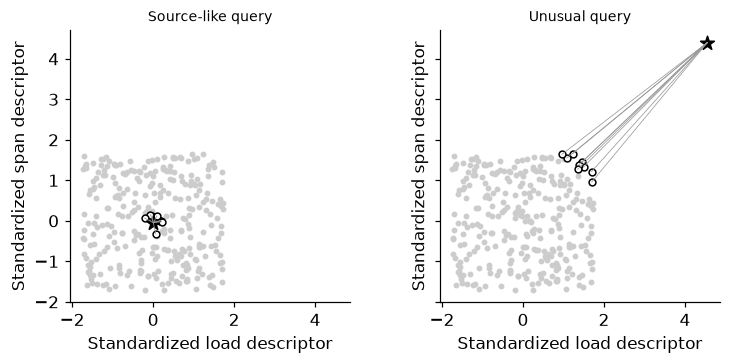

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor,NearestNeighbors
from sklearn.metrics import mean_squared_error
def generate(n,low=0,high=1):
 x=rng.uniform(low,high,(n,2));return x,np.sin(5*x[:,0])+.6*x[:,1]+rng.normal(0,.15,n)
X,y=generate(300);Xd,yd=generate(120);Xi,yi=generate(200);Xu,yu=generate(40,1.5,2);sc=StandardScaler().fit(X);S=sc.transform(X);D=sc.transform(Xd);candidates=[]
for k in [3,9,25]:
 for weight in ['uniform','distance']:
  model=KNeighborsRegressor(k,weights=weight).fit(S,y);candidates.append((float(mean_squared_error(yd,model.predict(D))),k,weight))
score,k,weight=min(candidates);model=KNeighborsRegressor(k,weights=weight).fit(S,y);rows=[]
for label,a,b in [('Inside',Xi,yi),('Unusual',Xu,yu)]:
 query=sc.transform(a);dist,ids=model.kneighbors(query);assert ids.shape==(len(a),k) and np.all(ids<len(y));rows.append({'cohort':label,'rows':len(a),'mse':float(mean_squared_error(b,model.predict(query))),'mean_kth_neighbor_distance':float(dist[:,-1].mean()),'max_kth_neighbor_distance':float(dist[:,-1].max())})
RESULTS['selection']={'development_mse':score,'k':k,'weights':weight,'candidate_scores':[{'development_mse':v,'k':j,'weights':w} for v,j,w in candidates]};RESULTS['final_cohorts']=rows;RESULTS['roles']={'training':300,'development':120,'inside_final':200,'unusual_final':40}
q=sc.transform(np.array([[.5,.5],[1.8,1.8]]));fig,axes=plt.subplots(1,2,figsize=(7,3.2),sharex=True,sharey=True)
for ax,point,title in zip(axes,q,['Source-like query','Unusual query']):
 dist,ids=model.kneighbors(point[None,:]);ax.scatter(*S.T,s=8,color='.8');ax.scatter(*S[ids[0]].T,s=20,facecolors='white',edgecolors='black');ax.scatter(*point,marker='*',s=90,color='black')
 for j in ids[0]:ax.plot([point[0],S[j,0]],[point[1],S[j,1]],color='.6',lw=.5)
 ax.set(title=title,xlabel='Standardized load descriptor',ylabel='Standardized span descriptor',aspect='equal')
plt.show()


<a id="search"></a>
## Search accuracy is separate from predictive quality

Exact brute-force and KD-tree retrieval should agree for these continuous two-dimensional queries. A deliberately coarse approximation searches one predeclared hundred-record subset of training memory. Report exact top-five recall and prediction error, while keeping the previously selected neighborhood/weighting fixed. This candidate-subset audit is not an HNSW/FAISS implementation or a sublinear-index guarantee. Distance-evaluation counts describe this comparison, not wall-time speedups. A separate tiny zero-distance fixture verifies that distance weighting averages exact duplicate locations instead of dividing by zero; it does not justify retaining duplicate field records as independent evidence.


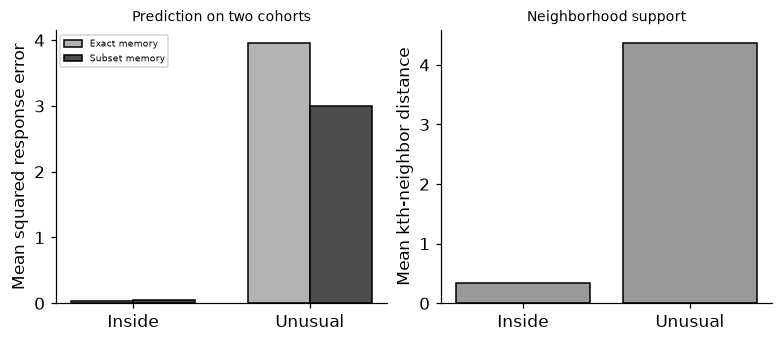

In [3]:
queries=sc.transform(np.vstack([Xi,Xu]));brute=NearestNeighbors(n_neighbors=5,algorithm='brute').fit(S);tree=NearestNeighbors(n_neighbors=5,algorithm='kd_tree').fit(S);db,ib=brute.kneighbors(queries);dt,it=tree.kneighbors(queries);np.testing.assert_array_equal(ib,it);np.testing.assert_allclose(db,dt,atol=1e-12)
subset=rng.choice(len(y),100,replace=False);approx=NearestNeighbors(n_neighbors=5,algorithm='brute').fit(S[subset]);_,local=approx.kneighbors(queries);approx_ids=subset[local];recall=float(np.mean([len(set(a)&set(b))/5 for a,b in zip(ib,approx_ids)]));approx_model=KNeighborsRegressor(k,weights=weight).fit(S[subset],y[subset]);approx_rows=[]
for label,a,b in [('Inside',Xi,yi),('Unusual',Xu,yu)]:approx_rows.append({'cohort':label,'mse':float(mean_squared_error(b,approx_model.predict(sc.transform(a))))})
toy=KNeighborsRegressor(3,weights='distance').fit([[0.],[0.],[1.]],[1.,3.,10.]);np.testing.assert_allclose(toy.predict([[0.]]),[2.]);assert 0<=recall<=1
RESULTS['search']={'exact_brute_KDtree_agreement':True,'subset_records':100,'full_records':300,'mean_top5_recall':recall,'distance_candidates_per_query_exact':300,'distance_candidates_per_query_subset':100,'subset_prediction':approx_rows,'algorithm_claim':'uniform candidate-subset demonstration only','duplicate_zero_distance_prediction':2.}
fig,axes=plt.subplots(1,2,figsize=(7,3));p=np.arange(2)
for j,(name,data) in enumerate([('Exact memory',rows),('Subset memory',approx_rows)]):axes[0].bar(p+(j-.5)*.35,[r['mse'] for r in data],width=.35,color=['.7','.3'][j],edgecolor='black',label=name)
axes[0].set(xticks=p,xticklabels=['Inside','Unusual'],ylabel='Mean squared response error',title='Prediction on two cohorts');axes[0].legend(fontsize=6);axes[1].bar(p,[r['mean_kth_neighbor_distance'] for r in rows],color='.6',edgecolor='black');axes[1].set(xticks=p,xticklabels=['Inside','Unusual'],ylabel='Mean kth-neighbor distance',title='Neighborhood support');plt.show()


In [4]:
summary={'example_id':'code_083','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['development neighborhood and weighting selection', 'inside versus unusual query support', 'exact tree versus brute retrieval', 'candidate-subset approximation and zero-distance behavior'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["development neighborhood and weighting selection", "inside versus unusual query support", "exact tree versus brute retrieval", "candidate-subset approximation and zero-distance behavior"], "elapsed_seconds": 0.304, "example_id": "code_083", "hardware": "Darwin arm64 CPU", "results": {"final_cohorts": [{"cohort": "Inside", "max_kth_neighbor_distance": 0.5700481121141091, "mean_kth_neighbor_distance": 0.34558874824950175, "mse": 0.03130193480173695, "rows": 200}, {"cohort": "Unusual", "max_kth_neighbor_distance": 5.186583897747085, "mean_kth_neighbor_distance": 4.361285473261903, "mse": 3.951933500480041, "rows": 40}], "roles": {"development": 120, "inside_final": 200, "training": 300, "unusual_final": 40}, "search": {"algorithm_claim": "uniform candidate-subset demonstration only", "distance_candidates_per_query_exact": 300, "distance_candidates_per_query_subset": 100, "duplicate_zero_distance_prediction": 2.0, "exact_brute_KDtree_agree